## Modelling and evaluation

This notebook builds, compares, and evaluates models for reported crop loss.

Households will be separated into training and final test sets. Model selection will use grouped cross-validation within the training set. The final test set will be reserved for evaluating the selected approach.

### 1. Load the modelling table and define the evaluation question

Load the saved table from notebook 02. Identify the target, predictors, household grouping key, and the intended use of predictions.

#### 1.1 Load the data

I load the modelling table saved by notebook 02 and check its basic structure.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_validate

DATA_FILE = Path("data/processed/modelling_data.csv")

TARGET = "reported_loss"
HOUSEHOLD_ID_COLUMN = "hhid"
RANDOM_STATE = 42

# Check that notebook 02's output is available.
if not DATA_FILE.is_file():
  raise FileNotFoundError(
    f"Cannot find {DATA_FILE.resolve()}. "
    "Check the working directory and notebook 02's saved output."
  )

# Read household IDs as text because they identify households,
# rather than representing quantities for the model.
model_data = pd.read_csv(
  DATA_FILE,
  dtype={HOUSEHOLD_ID_COLUMN: "string"}
)

# Confirm the expected structure before modelling.
assert not model_data.isna().any().any()
assert not model_data.duplicated([HOUSEHOLD_ID_COLUMN, "crop"]).any()
assert model_data[TARGET].isin(["Yes", "No"]).all()

print("Table shape:", model_data.shape)
display(model_data.head(3))

Table shape: (334133, 13)


,hhid,zone,state,sector,survey_weight,crop,reported_loss,crop_planted_area_m2,crop_plot_count,owned_plot_share,irrigation_infrastructure_share,farm_recordkeeping,listed_plot_count
0,326074.0,1.0,NASARAWA,URBAN,43.316891,RICE,No,2354.900000,1,1.0,0.0,PARTIALLY,3.0
1,342175.0,1.0,PLATEAU,RURAL,185.124704,RICE,No,11235.000000,1,0.0,0.0,"NO, NEVER",5.0
2,274109.0,3.0,KEBBI,URBAN,153.188059,GUINEA CORN/SORGHUM,No,17783.999629,2,1.0,0.0,OCCASIONALLY,2.0


#### 1.2 Separate predictors, target, and household identifiers

Explicitly list categorical and numeric predictors. Zone is treated as categorical even though its values are stored as numbers.

The target is encoded as 0 for no reported loss and 1 for reported loss. Household identifiers and sampling weights are excluded from the predictors.

In [2]:
# These values represent categories rather than measured amounts
CATEGORICAL_PREDICTORS = [
  "zone",
  "state",
  "sector",
  "crop",
  "farm_recordkeeping"
]

# These values represent counts, areas, or proportions
NUMERIC_PREDICTORS = [
  "listed_plot_count",
  "crop_planted_area_m2",
  "crop_plot_count",
  "owned_plot_share",
  "irrigation_infrastructure_share"
]

PREDICTORS = CATEGORICAL_PREDICTORS + NUMERIC_PREDICTORS

# X contains only the information supplied to the model
X = model_data[PREDICTORS].copy()

# y contains the outcome: 1 means reported loss, the positive class
y = model_data[TARGET].map({"No": 0, "Yes": 1}).astype(int)

# Keep household IDs separately for splitting and validation
household_ids = model_data[HOUSEHOLD_ID_COLUMN].copy()

print("Number of predictors:", X.shape[1])
print("\nTarget counts: 0 = no loss, 1 = loss")
display(y.value_counts().sort_index())

Number of predictors: 10

Target counts: 0 = no loss, 1 = loss


reported_loss
0    295686
1     38447
Name: count, dtype: int64

### 2. Reserve a test set and define grouped validation

Keep all records from a household in one partition. Check class balance and household separation. Reserve the test set before comparing models.

#### 2.1 Separate training and final test households

I reserve approximately 20% of households for final testing and use the remaining households for training and model selection.

All records belonging to a household stay in the same set. This allows evaluation on households not encountered during training.

The random seed makes the split reproducible for the same input data.

In [3]:
# Select 20% of households for testing.
# The percentage applies to households, not individual crop records.
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

# Obtain the row positions belonging to each set.
train_idx, test_idx = next(
    splitter.split(X, y, groups=household_ids) # groups keep rows with same household ID together.
)

# .iloc selects rows by their positions.
# Use the same positions for predictors, targets, and household IDs.
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

household_ids_train = household_ids.iloc[train_idx].copy()
household_ids_test = household_ids.iloc[test_idx].copy()

# No household should appear in both sets.
assert set(household_ids_train).isdisjoint(set(household_ids_test)), (
    "A household appears in both training and test data."
)

# Confirm that every record was assigned and both outcomes are represented.
assert len(X_train) + len(X_test) == len(X)
assert y_train.nunique() == 2
assert y_test.nunique() == 2

print("Split checks passed: no household overlap.")

Split checks passed: no household overlap.


In [4]:
# Compare set sizes and the percentage of records reporting loss.
# Because y contains zeroes and ones, its mean is the loss proportion.
split_summary = pd.DataFrame({
    "records": [len(X_train), len(X_test)],
    "households": [
        household_ids_train.nunique(),
        household_ids_test.nunique()
    ],
    "loss_percent": [
        y_train.mean() * 100,
        y_test.mean() * 100
    ]
}, index=["Training", "Final test"]).round(2)

display(split_summary)

,records,households,loss_percent
Training,267479,93124,11.51
Final test,66654,23282,11.50


The data was separated into training and final test sets with no household overlap. Both sets contain records with and without reported loss.

The final test set will remain reserved during model selection. Encoding, scaling, and other learned preprocessing will be fitted within training pipelines. Grouped cross-validation will be used within the training set.

#### 2.2 Set up grouped cross-validation

I divide the training data into five validation folds. Each model is trained on four folds and evaluated on the remaining fold, repeating five times.

Records from the same household remain together. The split also attempts to keep the loss proportions similar across folds.

The same folds will be used when comparing models. The final test set is not used here.

In [5]:
# Create five folds while keeping each household's records together.
validation_splitter = StratifiedGroupKFold(
  n_splits=5,
  shuffle=True,
  random_state=RANDOM_STATE
)

# Save the row positions so later models use exactly the same folds.
validation_folds = list(
  validation_splitter.split(
    X_train,
    y_train,
    groups=household_ids_train
  )
)

# Retrieve the first pair of row-position arrays.
fitting_rows, validation_rows = validation_folds[0]

# Show only the first ten positions from each array.
print("Fitting positions:", fitting_rows[:10])
print("Validation positions:", validation_rows[:10])

# Confirm household separation within every fold.
for fitting_rows, validation_rows in validation_folds:
  fitting_households = set(
    household_ids_train.iloc[fitting_rows]
  )
  validation_households = set(
    household_ids_train.iloc[validation_rows]
  )

  assert fitting_households.isdisjoint(validation_households)

print("Five validation folds created with no household overlap.")

Fitting positions: [ 0  2  3  4  5  6  7  9 10 11]
Validation positions: [ 1  8 14 21 29 30 34 35 40 46]
Five validation folds created with no household overlap.


### 3. Build a dummy baseline and logistic regression

Lifecycle stage 3. Explain the benchmarks. Fit learned preprocessing only on training data through model pipelines.

#### 3.1 Establish the dummy benchmark

The dummy classifier predicts the most frequent outcome in its fitting data. It ignores the predictor values and provides a simple comparison point.

I measure accuracy and positive-class precision, recall, and F1-score. The positive class is reported loss, encoded as 1.

When no losses are predicted, precision is undefined. I report it as zero using the zero_division setting.

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
  make_scorer,
  precision_score,
  recall_score,
  f1_score
)

# Define the scores used consistently for model comparisons.
# The binary metrics evaluate reported loss, encoded as 1.
scoring = {
  "accuracy": "accuracy",
  "precision": make_scorer(precision_score, zero_division=0),
  "recall": make_scorer(recall_score, zero_division=0),
  "f1": make_scorer(f1_score, zero_division=0)
}

# Predict the most common outcome without using crop or farm characteristics.
dummy_model = DummyClassifier(strategy="most_frequent")

# Fit and evaluate a fresh dummy model in each validation fold.
# Only training data is supplied; X_test and y_test remain unused.
dummy_cv_results = cross_validate(
  dummy_model,
  X_train,
  y_train,
  cv=validation_folds,
  scoring=scoring,
  error_score="raise"
)

In [7]:
# Collect the validation scores from each fold.
# "test_" is scikit-learn's name for validation-fold scores here.
# It does not refer to our reserved final test set.
dummy_fold_scores = pd.DataFrame({
  "accuracy": dummy_cv_results["test_accuracy"],
  "precision": dummy_cv_results["test_precision"],
  "recall": dummy_cv_results["test_recall"],
  "f1": dummy_cv_results["test_f1"]
}, index=range(1, 6))

dummy_fold_scores.index.name = "fold"

display(dummy_fold_scores.round(3))

# Show average performance and variation across the five folds.
dummy_summary = pd.DataFrame({
  "mean_score": dummy_fold_scores.mean(),
  "std": dummy_fold_scores.std()
})

display(dummy_summary.round(3))

,accuracy,precision,recall,f1
fold,,,,
1,0.883,0.0,0.0,0.0
2,0.886,0.0,0.0,0.0
3,0.887,0.0,0.0,0.0
4,0.884,0.0,0.0,0.0
5,0.885,0.0,0.0,0.0


,mean_score,std
accuracy,0.885,0.001
precision,0.000,0.000
recall,0.000,0.000
f1,0.000,0.000


The dummy classifier achieves high accuracy by predicting the majority no-loss class. However, it identifies none of the reported-loss records, giving zero recall and F1-score for loss. Precision is reported as zero
under the stated convention.

This confirms that accuracy alone is insufficient. Subsequent models must be assessed for their ability to identify losses and the false positives they produce.

#### 3.2 Prepare predictors for logistic regression

Logistic regression requires numeric inputs. I use one-hot encoding for categorical predictors and standard scaling for numeric predictors.

The preprocessing steps are defined here. They will be fitted inside the model pipeline during cross-validation, using only each fold's fitting data.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

assert set(CATEGORICAL_PREDICTORS + NUMERIC_PREDICTORS) == set(
  X_train.columns
)

# Convert each categorical value into a separate 0/1 column.
# Allow validation records to contain categories absent from the fitting data.
categorical_encoder = OneHotEncoder(handle_unknown="ignore")

# Standardise numeric columns using their fitting-data means and standard deviations.
numeric_scaler = StandardScaler()

# Apply the appropriate operation to each named group of columns.
preprocessor = ColumnTransformer(
  transformers=[
    (
      "categorical",
      categorical_encoder,
      CATEGORICAL_PREDICTORS
    ),
    (
      "numeric",
      numeric_scaler,
      NUMERIC_PREDICTORS
    )
  ],
  remainder="drop"
)

print("Preprocessing configured.")

Preprocessing configured.


The preprocessing configuration applies one-hot encoding to categorical predictors and standard scaling to numeric predictors.

No preprocessing parameters have been learned yet. These steps will be combined with logistic regression so that encoding and scaling are fitted separately within each cross-validation run.

#### 3.3 Train and validate logistic regression

Logistic regression learns relationships between the predictors and the probability of reported loss.

I combine preprocessing and classification in one pipeline. During each validation round, preprocessing and model fitting use only the fitting
records.

I use the same five folds and metrics as the dummy benchmark.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Process the predictors first, then fit logistic regression
logistic_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [10]:
# Fit and evaluate a fresh pipeline in each saved validation fold.
# cross_validate performs the fitting
logistic_cv_results = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=validation_folds,
    scoring=scoring,
    error_score="raise"
)

In [11]:
# Collect one score per fold for each metric.
# "test_" refers to validation-fold scores, not the reserved final test set.
logistic_fold_scores = pd.DataFrame({
    "accuracy": logistic_cv_results["test_accuracy"],
    "precision": logistic_cv_results["test_precision"],
    "recall": logistic_cv_results["test_recall"],
    "f1": logistic_cv_results["test_f1"]
}, index=range(1, len(validation_folds) + 1))

logistic_fold_scores.index.name = "fold"

display(logistic_fold_scores.round(3))

# Summarise average performance and variation between folds.
logistic_summary = pd.DataFrame({
    "mean_score": logistic_fold_scores.mean(),
    "std": logistic_fold_scores.std()
})

display(logistic_summary.round(3))

,accuracy,precision,recall,f1
fold,,,,
1,0.884,0.821,0.004,0.007
2,0.886,0.733,0.004,0.007
3,0.887,0.778,0.003,0.007
4,0.884,0.903,0.005,0.009
5,0.885,0.571,0.001,0.003


,mean_score,std
accuracy,0.885,0.001
precision,0.761,0.123
recall,0.003,0.001
f1,0.007,0.002


In [12]:
# Place the average validation scores side by side.
model_comparison = pd.DataFrame({
    "Dummy": dummy_summary["mean_score"],
    "Logistic regression": logistic_summary["mean_score"]
})

display(model_comparison.round(3))

,Dummy,Logistic regression
accuracy,0.885,0.885
precision,0.000,0.761
recall,0.000,0.003
f1,0.000,0.007


Logistic regression achieved mean validation precision of 0.761, recall of 0.003, and F1-score of 0.007.

Compared with the dummy benchmark, logistic regression identified some losses, but the improvement was limited. Its high precision means that predicted losses were usually correct. However, it detected only about 0.3% of actual
loss records at the default decision threshold. The very low F1-score reflects this poor loss detection. Accuracy remained approximately 88.5%, similar to the dummy benchmark.

These results come from grouped cross-validation within the training data. The final test set has not been used.

#### 3.4 Test class-balanced logistic regression

The original logistic regression model detected very few losses. Test whether class weighting improves loss detection using the preprocessing, validation folds, and scoring. Only class_weight is changed to "balanced".

In [13]:
from sklearn.base import clone

# Create a separate, unfitted copy of the original pipeline.
balanced_logistic_model = clone(logistic_model)

# Change class_weight in the pipeline step named "classifier".
# The double underscore connects the step name to its parameter.
balanced_logistic_model.set_params(
  classifier__class_weight="balanced"
)

# Train and evaluate using exactly the same folds and metrics.
balanced_cv_results = cross_validate(
  balanced_logistic_model,
  X_train,
  y_train,
  cv=validation_folds,
  scoring=scoring,
  error_score="raise"
)

In [14]:
# Collect the validation scores for each fold.
balanced_fold_scores = pd.DataFrame({
  "accuracy": balanced_cv_results["test_accuracy"],
  "precision": balanced_cv_results["test_precision"],
  "recall": balanced_cv_results["test_recall"],
  "f1": balanced_cv_results["test_f1"]
}, index=range(1, len(validation_folds) + 1))

balanced_fold_scores.index.name = "fold"

display(balanced_fold_scores.round(3))

# Calculate average performance and variation across folds.
balanced_summary = pd.DataFrame({
  "mean_score": balanced_fold_scores.mean(),
  "std": balanced_fold_scores.std()
})

display(balanced_summary.round(3))

,accuracy,precision,recall,f1
fold,,,,
1,0.643,0.197,0.671,0.304
2,0.647,0.193,0.661,0.299
3,0.641,0.190,0.665,0.296
4,0.642,0.193,0.653,0.298
5,0.642,0.193,0.660,0.299


,mean_score,std
accuracy,0.643,0.002
precision,0.193,0.002
recall,0.662,0.007
f1,0.299,0.003


In [15]:
# Compare average scores using the same validation records.
model_comparison = pd.DataFrame({
  "Dummy": dummy_summary["mean_score"],
  "Original logistic": logistic_summary["mean_score"],
  "Balanced logistic": balanced_summary["mean_score"]
})

display(model_comparison.round(3))

,Dummy,Original logistic,Balanced logistic
accuracy,0.885,0.885,0.643
precision,0.000,0.761,0.193
recall,0.000,0.003,0.662
f1,0.000,0.007,0.299


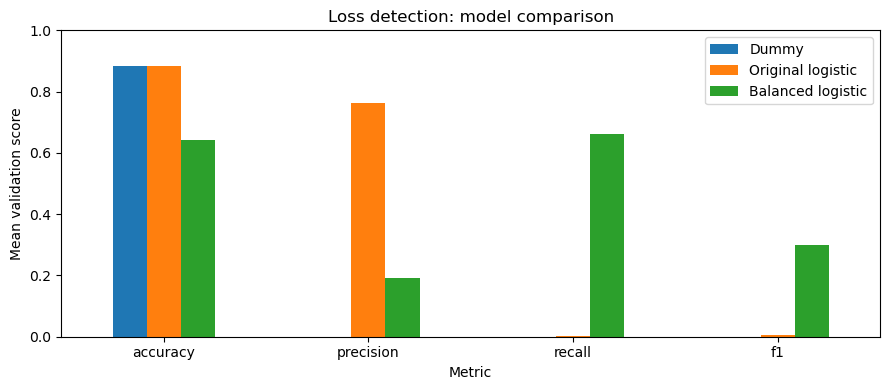

In [17]:
import matplotlib.pyplot as plt

# Compare the three metrics focused on reported loss.
ax = model_comparison.loc[
  ["accuracy", "precision", "recall", "f1"]
].plot.bar(figsize=(9, 4), rot=0)

ax.set(
  title="Loss detection: model comparison",
  xlabel="Metric",
  ylabel="Mean validation score",
  ylim=(0, 1)
)

plt.tight_layout()
plt.show()

Class-balanced logistic regression achieved mean precision of 0.193, recall of 0.662, and F1-score of 0.299.

Compared with the original model, recall increased from 0.003 to 0.662 and F1 increased from 0.007 to 0.299. However, precision fell from 0.761 to 0.193 and accuracy fell from 0.885 to 0.643.

Class weighting substantially improved loss detection, but most predicted losses were false alarms. Whether this tradeoff is acceptable depends on the costs of missed losses and unnecessary interventions.

### 4. Compare additional models

Compare random forest and, if justified, gradient boosting using the same validation folds and metrics.

#### 4.1 Train and validate random forest

Test whether random forest improves loss detection compared with the logistic regression models.

Class weighting addresses the unequal class frequencies. Tree depth and minimum leaf size are limited to control model complexity.

These are initial settings, not optimised settings.

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Encode categories, but leave numeric values unchanged
# Random forest does not require standard scaling
forest_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_encoder,
            CATEGORICAL_PREDICTORS
        ),
        (
            "numeric",
            "passthrough",  # means keep those columns unchanged
            NUMERIC_PREDICTORS
        )
    ],
    remainder="drop"
)

In [ ]:
forest_model = Pipeline(steps=[
    ("preprocessing", forest_preprocessor),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=200,        # Build 200 decision trees.
            max_depth=15,            # Limit how deep each tree can grow.
            min_samples_leaf=10,     # Require at least 10 records per leaf. Helps overfitting
            class_weight="balanced",  # Give rarer loss records more weight.
            random_state=RANDOM_STATE,
            n_jobs=-1               # Use available processors for the trees.
        )
    )
])

In [20]:
# Evaluate the same five folds used for the other models
# Process folds sequentially; the forest parallelises its trees
forest_cv_results = cross_validate(
  forest_model,
  X_train,
  y_train,
  cv=validation_folds,
  scoring=scoring,
  n_jobs=1,
  error_score="raise"
)

In [21]:
# Collect each fold's validation scores.
forest_fold_scores = pd.DataFrame({
    "accuracy": forest_cv_results["test_accuracy"],
    "precision": forest_cv_results["test_precision"],
    "recall": forest_cv_results["test_recall"],
    "f1": forest_cv_results["test_f1"]
}, index=range(1, len(validation_folds) + 1))

forest_fold_scores.index.name = "fold"

display(forest_fold_scores.round(3))

# Summarise average performance and variation across folds.
forest_summary = pd.DataFrame({
    "mean_score": forest_fold_scores.mean(),
    "std": forest_fold_scores.std()
})

display(forest_summary.round(3))

,accuracy,precision,recall,f1
fold,,,,
1,0.679,0.220,0.692,0.334
2,0.682,0.218,0.689,0.331
3,0.673,0.210,0.686,0.322
4,0.672,0.214,0.682,0.326
5,0.680,0.216,0.676,0.327


,mean_score,std
accuracy,0.677,0.005
precision,0.216,0.004
recall,0.685,0.006
f1,0.328,0.005


In [22]:
model_comparison = pd.DataFrame({
    "Dummy": dummy_summary["mean_score"],
    "Original logistic": logistic_summary["mean_score"],
    "Balanced logistic": balanced_summary["mean_score"],
    "Balanced forest": forest_summary["mean_score"]
})

display(model_comparison.round(3))

,Dummy,Original logistic,Balanced logistic,Balanced forest
accuracy,0.885,0.885,0.643,0.677
precision,0.000,0.761,0.193,0.216
recall,0.000,0.003,0.662,0.685
f1,0.000,0.007,0.299,0.328


Random forest achieved mean validation precision of 0.216, recall of 0.685, and F1-score of 0.328.

Compared with balanced logistic regression, precision increased from 0.193 to 0.216, recall increased from 0.662 to 0.685, and F1 increased from 0.299 to 0.328. Accuracy also increased from 0.643 to 0.677.

The forest provides a better precision-recall tradeoff under the tested settings. However, most predicted losses remain false alarms, so its practical usefulness depends on the cost of unnecessary interventions.

Scores varied little across the five validation folds.

#### 4.2 Compare random forest settings

I compare two maximum tree depths and two minimum leaf sizes.

Deeper trees allow more detailed patterns, while larger minimum leaf sizes require more records to support each prediction.

The search includes the original configuration. Preprocessing, class weighting, tree count, and validation folds remain unchanged.

Settings are ranked by mean validation F1-score. Precision and recall are also examined.

In [23]:
from sklearn.model_selection import GridSearchCV

# Compare every combination of these settings: 2 × 2 = 4 configurations
# The original settings, depth 15 and minimum leaf size 10, are included
parameter_grid = {
    "classifier__max_depth": [15, 25],
    "classifier__min_samples_leaf": [10, 30]
}

forest_search = GridSearchCV(
    estimator=clone(forest_model),
    param_grid=parameter_grid,
    scoring=scoring,
    refit="f1",               # Select the setting with the highest mean F1
    cv=validation_folds,     # Reuse our household-separated folds
    # Run searches sequentially; trees use parallelism
    n_jobs=1,
    error_score="raise",
    verbose=1                # Print the number of configurations and fits
)

# Train and validate all four configurations
forest_search.fit(X_train, y_train)

Fitting 5 folds for each of 4 candidates, totalling 20 fits


GridSearchCV(cv=[(array([     0,      2,      3, ..., 267476, 267477, 267478]),
                  array([     1,      8,     14, ..., 267457, 267458, 267472])),
                 (array([     0,      1,      2, ..., 267476, 267477, 267478]),
                  array([     6,     15,     19, ..., 267454, 267466, 267467])),
                 (array([     0,      1,      2, ..., 267476, 267477, 267478]),
                  array([    12,     20,     26, ..., 267469, 267473, 267474])),
                 (array([     0,      1,      4, ..., 267472, 267473, 267474]),
                  array([     2,      3,      5, ..., 267476, 267477, 267478]))...
             param_grid={'classifier__max_depth': [15, 25],
                         'classifier__min_samples_leaf': [10, 30]},
             refit='f1',
             scoring={'accuracy': 'accuracy',
                      'f1': make_scorer(f1_score, response_method='predict', zero_division=0),
                      'precision': make_scorer(precision_score, response_method='predict', zero_division=0),
                      'recall': make_scorer(recall_score, response_method='predict', zero_division=0)},
             verbose=1)

In [24]:
# Convert the search output into a table.
search_results = pd.DataFrame(forest_search.cv_results_)

# Keep the settings and validation scores we want to compare.
search_summary = pd.DataFrame({
    "max_depth": search_results["param_classifier__max_depth"],
    "min_leaf": search_results["param_classifier__min_samples_leaf"],
    "accuracy": search_results["mean_test_accuracy"],
    "precision": search_results["mean_test_precision"],
    "recall": search_results["mean_test_recall"],
    "f1": search_results["mean_test_f1"],
    "f1_std": search_results["std_test_f1"]
}).sort_values("f1", ascending=False)

display(search_summary.round(3))

print("Best settings:", forest_search.best_params_)
print("Best mean validation F1:", round(forest_search.best_score_, 3))

,max_depth,min_leaf,accuracy,precision,recall,f1,f1_std
2,25,10,0.707,0.233,0.674,0.346,0.005
3,25,30,0.682,0.219,0.687,0.332,0.005
0,15,10,0.677,0.216,0.685,0.328,0.004
1,15,30,0.667,0.211,0.688,0.323,0.005


Best settings: {'classifier__max_depth': 25, 'classifier__min_samples_leaf': 10}
Best mean validation F1: 0.346


In [25]:
# Retrieve the winning configuration's original results row.
winning_result = search_results.iloc[forest_search.best_index_]

# Store its mean validation scores using the same metric names as before.
tuned_forest_scores = pd.Series({
    "accuracy": winning_result["mean_test_accuracy"],
    "precision": winning_result["mean_test_precision"],
    "recall": winning_result["mean_test_recall"],
    "f1": winning_result["mean_test_f1"]
})

model_comparison["Tuned forest"] = tuned_forest_scores

display(model_comparison.round(3))

# Keep the fitted candidate available for later model selection.
tuned_forest_model = forest_search.best_estimator_

,Dummy,Original logistic,Balanced logistic,Balanced forest,Tuned forest
accuracy,0.885,0.885,0.643,0.677,0.707
precision,0.000,0.761,0.193,0.216,0.233
recall,0.000,0.003,0.662,0.685,0.674
f1,0.000,0.007,0.299,0.328,0.346


Among the four tested configurations, the highest mean validation F1-score was 0.346, using maximum depth 25 and minimum leaf size 10.

Compared with the initial forest, precision increased from 0.216 to 0.233, while recall decreased slightly from 0.685 to 0.674. F1 increased from 0.328 to 0.346, indicating an improved precision-recall balance under the tested settings. Accuracy increased from 0.677 to 0.707.

False alarms remain frequent despite the improvement. The selected configuration was refitted on all training records, and the final test set has not been used.

#### 4.3 Compare basic and full predictor sets

I compare crop-and-location predictors with the full predictor set to assess whether household and farm information improves predictions.

Both models use the same validation folds and forest settings. These settings were selected using the full predictor set, so this comparison describes performance under that configuration.

In [26]:
# Select only crop and location information.
BASIC_PREDICTORS = ["zone", "state", "sector", "crop"]

# Selecting columns preserves the rows and their order
# The saved validation-fold positions therefore remain valid
X_train_basic = X_train[BASIC_PREDICTORS].copy()

# All four basic predictors represent categories.
basic_preprocessor = ColumnTransformer(
  transformers=[
    (
      "categorical",
      OneHotEncoder(handle_unknown="ignore"),
      BASIC_PREDICTORS
    )
  ],
  remainder="drop"
)

# Copy the tuned forest's settings without copying its fitted state.
basic_forest_model = clone(tuned_forest_model)

# Replace preprocessing so it handles only the basic predictors.
basic_forest_model.set_params(
  preprocessing=basic_preprocessor
)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['zone', 'state', 'sector',
                                                   'crop'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced', max_depth=25,
                                        min_samples_leaf=10, n_estimators=200,
                                        n_jobs=-1, random_state=42))])

In [27]:
# Evaluate the basic predictors using the same folds and scoring.
basic_cv_results = cross_validate(
  basic_forest_model,
  X_train_basic,
  y_train,
  cv=validation_folds,
  scoring=scoring,
  n_jobs=1,
  error_score="raise"
)

In [ ]:
# Collect the basic model's scores for each validation fold
basic_fold_scores = pd.DataFrame({
    "accuracy": basic_cv_results["test_accuracy"],
    "precision": basic_cv_results["test_precision"],
    "recall": basic_cv_results["test_recall"],
    "f1": basic_cv_results["test_f1"]
}, index=range(1, len(validation_folds) + 1))

basic_fold_scores.index.name = "fold"

display(basic_fold_scores.round(3))

# Summarise average performance and variation
basic_summary = pd.DataFrame({
    "mean_score": basic_fold_scores.mean(),
    "std": basic_fold_scores.std()
})

# Reuse the full model's validation scores from the tuning step
feature_comparison = pd.DataFrame({
    "Crop + location": basic_summary["mean_score"],
    "Full predictors": tuned_forest_scores
})

display(feature_comparison.round(3))

,accuracy,precision,recall,f1
fold,,,,
1,0.650,0.203,0.680,0.312
2,0.656,0.200,0.670,0.308
3,0.651,0.195,0.669,0.303
4,0.652,0.199,0.659,0.306
5,0.657,0.199,0.655,0.305


,Crop + location,Full predictors
accuracy,0.653,0.707
precision,0.199,0.233
recall,0.667,0.674
f1,0.307,0.346


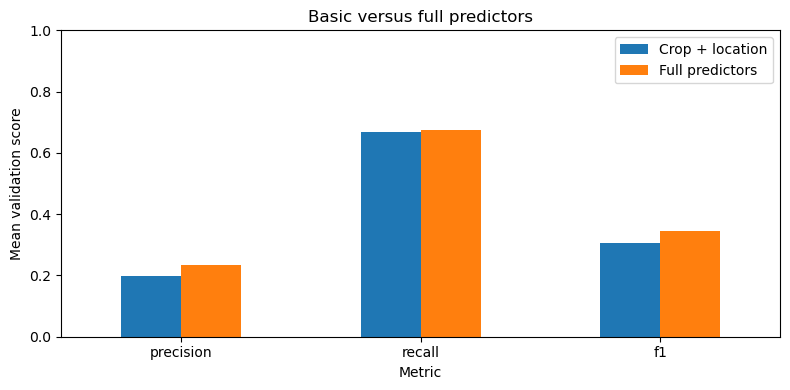

In [29]:
import matplotlib.pyplot as plt

# Compare performance on the reported-loss class.
ax = feature_comparison.loc[
    ["precision", "recall", "f1"]
].plot.bar(figsize=(8, 4), rot=0)

ax.set(
    title="Basic versus full predictors",
    xlabel="Metric",
    ylabel="Mean validation score",
    ylim=(0, 1)
)

plt.tight_layout()
plt.show()

Using crop and location alone, the forest achieved mean precision of 0.199, recall of 0.667, and F1-score of 0.307.

With the full predictor set, precision increased to 0.233, recall to 0.674, and F1 to 0.346. Accuracy increased from 0.653 to 0.707.

Under the chosen forest settings, household and farm information improved predictions, particularly precision. However, most loss alerts remained false alarms.

This comparison used settings selected with the full predictor set. It does not establish which individual additional variables produced the improvement.

### 5. Select the model and evaluate it

Lifecycle stage 4. Use validation results to select the model and any threshold. Evaluate the final selected approach on the reserved test set. Report positive-class precision, recall, F1, a confusion matrix, and suitable plots.

### 6. Investigate performance and errors

Lifecycle stage 5. Compare simple and expanded feature sets, inspect relevant crop/region differences, and interpret predictive importance without making unsupported causal claims. Do not retune models on the final test results.

### 7. Answer the research question and reflect

Lifecycle stage 5. Explain what the results support, their practical implications, limitations, ethical and societal considerations, and useful future work. Identify the findings to present orally.